::: {.callout-note title="Versión resuelta"}
Incluye los resultados de ejecutar cada celda: son las cifras y figuras del deck. Para trabajar con el cuaderno, [descárgalo sin resultados](../../clabs/02/tema_02_evaluacion_codigo.ipynb){download=""} o [ábrelo en Colab](https://colab.research.google.com/github/juanDmontoro/tap/blob/main/clabs/02/tema_02_evaluacion_codigo.ipynb).
:::

Este cuaderno reproduce, en el orden de las slides, las figuras y cifras del deck del tema 2. Usa los mismos datos, semillas y tamaños, así que los resultados coinciden con los de las slides.

- **Cómo usarlo**: ejecuta las celdas en orden (*Restart & Run All*). Cada sección indica a qué slide corresponde.
- **Entorno**: el del curso (`tap`): scikit-learn, pandas, numpy y matplotlib.
- **Tiempo**: menos de un minuto en un equipo de 12 núcleos; en un portátil, unos minutos. Las celdas lentas lo avisan.
- **Datos**: anuncios de Airbnb en Valencia (Inside Airbnb), los mismos de la semana 2 del tema 1. Se descargan de la web del curso.

El código prioriza la lectura: bucles explícitos, nombres descriptivos y un comentario por paso.

## 0. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, ShuffleSplit, LeaveOneOut,
                                     GridSearchCV, cross_val_score, cross_val_predict,
                                     TunedThresholdClassifierCV)
from sklearn.metrics import (root_mean_squared_error, confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score, log_loss,
                             precision_recall_curve, average_precision_score, make_scorer,
                             ConfusionMatrixDisplay)

# Colores del curso
AZUL, MARINO, TERRACOTA, SALVIA, GRIS = "#447099", "#1F3A5F", "#E07A5F", "#81B29A", "#6C757D"
plt.rcParams.update({"figure.figsize": (8, 5), "axes.spines.top": False, "axes.spines.right": False})

# Un barrio que no aparece al ajustar se codifica como fila de ceros; scikit-learn lo avisa en cada
# predicción. Es lo esperado, así que silenciamos ese aviso.
warnings.filterwarnings("ignore", message="Found unknown categories")

SEED = 42
N_TRAIN = 300        # anuncios del bloque 1 (los mismos de la semana 2)
N_SEMILLAS = 30      # repartos alternativos de los 300 anuncios (slide 2)
N_CONJUNTOS = 50     # conjuntos de 300 anuncios para estudiar la estimación (slides 6 y 7)

## 1. Datos

Misma población y misma división que la semana 2 del tema 1: anuncios entre 30 y 400 € por noche, alojamientos enteros y habitaciones privadas; un 30 % de los anuncios se reserva como conjunto de test.

In [2]:
URL_DATOS = "https://juandmontoro.github.io/tap/data/listados.csv"
columnas = ["neighbourhood_cleansed", "room_type", "latitude", "longitude", "accommodates",
            "bathrooms", "bedrooms", "beds", "number_of_reviews", "number_of_reviews_ltm",
            "reviews_per_month", "review_scores_rating", "minimum_nights", "availability_365",
            "host_is_superhost", "price"]
df = pd.read_csv(URL_DATOS, usecols=columnas)

# El precio viene como texto ("$1,200.00"): quitamos "$" y "," y lo pasamos a número
df["price"] = pd.to_numeric(df["price"].str.replace(r"[$,]", "", regex=True))

# Distancia al centro (plaza del Ayuntamiento) en km
lat0, lon0 = 39.4699, -0.3763
dif_norte = (df["latitude"] - lat0) * 111.0
dif_este = (df["longitude"] - lon0) * 111.0 * np.cos(np.radians(lat0))
df["dist_km"] = np.sqrt(dif_norte ** 2 + dif_este ** 2)

# Superanfitrión: 1 si "t", 0 en otro caso
df["superhost"] = (df["host_is_superhost"] == "t").astype(int)

# Población de estudio
en_rango = df["price"].between(30, 400)
tipo_valido = df["room_type"].isin(["Entire home/apt", "Private room"])
datos = df[en_rango & tipo_valido].copy()
datos["log_precio"] = np.log(datos["price"])
print("Anuncios:", len(datos))

Anuncios: 7606


In [3]:
num = ["dist_km", "accommodates", "bathrooms", "bedrooms", "beds", "number_of_reviews",
       "number_of_reviews_ltm", "reviews_per_month", "review_scores_rating", "minimum_nights",
       "availability_365", "superhost"]
cat = ["neighbourhood_cleansed", "room_type"]
features = num + cat

# División entrenamiento / test (el test no se usa hasta la actividad final)
entreno, test = train_test_split(datos, test_size=0.3, random_state=SEED)

# Bloque 1: los mismos 300 anuncios de la semana 2
train = entreno.sample(N_TRAIN, random_state=SEED)
X_train = train[features]
y_train = train["log_precio"]
print("Entrenamiento:", len(entreno), "| test:", len(test), "| anuncios del bloque 1:", len(train))

Entrenamiento: 5324 | test: 2282 | anuncios del bloque 1: 300


### Preprocesado y modelos de la semana 2

Imputación con la mediana y estandarización de las numéricas; variables ficticias para las categóricas, con una categoría de referencia (el barrio más frecuente y la habitación privada).

In [4]:
REF = [datos["neighbourhood_cleansed"].value_counts().idxmax(), "Private room"]


def preprocesador():
    numericas = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())])
    categoricas = OneHotEncoder(drop=REF, handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([("num", numericas, num), ("cat", categoricas, cat)])


def pipeline(modelo):
    return Pipeline([("prep", preprocesador()), ("model", modelo)])


ridge_grid = np.logspace(-2, 4, 25)      # alpha de Ridge
l1_grid = np.logspace(-4, 0, 25)         # alpha de Lasso y ElasticNet
specs = {
    "Ridge": (Ridge(), {"model__alpha": ridge_grid}),
    "Lasso": (Lasso(max_iter=50000, tol=1e-5), {"model__alpha": l1_grid}),
    "Elastic Net": (ElasticNet(max_iter=50000, tol=1e-5),
                    {"model__alpha": l1_grid, "model__l1_ratio": [0.1, 0.5, 0.9]}),
}


def busca(cv, X, y):
    """Las tres búsquedas en rejilla de la semana 2 con las particiones `cv`."""
    busquedas = {}
    for nombre, (modelo, rejilla) in specs.items():
        gs = GridSearchCV(pipeline(modelo), rejilla, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
        gs.fit(X, y)
        busquedas[nombre] = gs
    return busquedas

# Bloque 1. ¿Qué incertidumbre incorpora el error de validación?

## Slide 2. ¿Seguiría ganando el mismo modelo con otra partición?

Primero, la tabla de decisión de la semana 2: validación cruzada con 5 particiones (semilla 42).

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
searches = busca(cv, X_train, y_train)

filas = []
for nombre, gs in searches.items():
    k = gs.best_index_                                    # posición del mejor modelo en la rejilla
    mse_particiones = [-gs.cv_results_[f"split{i}_test_score"][k] for i in range(5)]
    rmse_particiones = np.sqrt(mse_particiones)
    coef = gs.best_estimator_["model"].coef_
    filas.append({"Familia": nombre,
                  "RMSE CV": np.sqrt(-gs.best_score_),
                  "EE CV": rmse_particiones.std(ddof=1) / np.sqrt(5),   # error típico (slide 7)
                  "Activas": int(np.sum(np.abs(coef) > 1e-8))})       # coeficientes no nulos
decision = pd.DataFrame(filas).set_index("Familia")
winner = decision["RMSE CV"].idxmin()
print("Ganador:", winner)
decision.round(4)

Ganador: Elastic Net


,RMSE CV,EE CV,Activas
Familia,,,
Ridge,0.4394,0.0225,73
Lasso,0.4219,0.0144,4
Elastic Net,0.4218,0.0156,5


Ahora repetimos la validación cruzada con otras semillas: los mismos 300 anuncios, repartidos de otra forma. **Celda lenta (1-2 min).**

In [6]:
ganadores = []
for semilla in range(N_SEMILLAS):
    cv_s = KFold(n_splits=5, shuffle=True, random_state=semilla)
    busquedas_s = busca(cv_s, X_train, y_train)
    mejor_score = {nombre: gs.best_score_ for nombre, gs in busquedas_s.items()}
    ganadores.append(max(mejor_score, key=mejor_score.get))   # mayor score = menor error

pd.Series(ganadores).value_counts()

Lasso          19
Elastic Net    11
Name: count, dtype: int64

## Slide 5. Una sola división frente a validación cruzada

El mismo Ridge (con la λ elegida en la semana 2) y los mismos 300 anuncios. Solo cambia el reparto: 100 semillas.

In [7]:
alpha_ridge = searches["Ridge"].best_params_["model__alpha"]
ridge_fijo = pipeline(Ridge(alpha=alpha_ridge))


def rmse_validacion(modelo, X, y, cv):
    """Raíz del MSE medio de validación y los MSE de cada partición."""
    mse = -cross_val_score(modelo, X, y, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
    return np.sqrt(mse.mean()), mse


una_division = []
cinco_particiones = []
for semilla in range(100):
    division = ShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla)       # una división 80/20
    una_division.append(rmse_validacion(ridge_fijo, X_train, y_train, division)[0])
    particiones = KFold(n_splits=5, shuffle=True, random_state=semilla)            # 5 particiones
    cinco_particiones.append(rmse_validacion(ridge_fijo, X_train, y_train, particiones)[0])
una_division = np.array(una_division)
cinco_particiones = np.array(cinco_particiones)

print("Desviación típica con una división:", round(una_division.std(), 3))
print("Desviación típica con 5 particiones:", round(cinco_particiones.std(), 3))
print("Cociente:", round(una_division.std() / cinco_particiones.std(), 1))

Desviación típica con una división: 0.058
Desviación típica con 5 particiones: 0.008
Cociente: 7.1


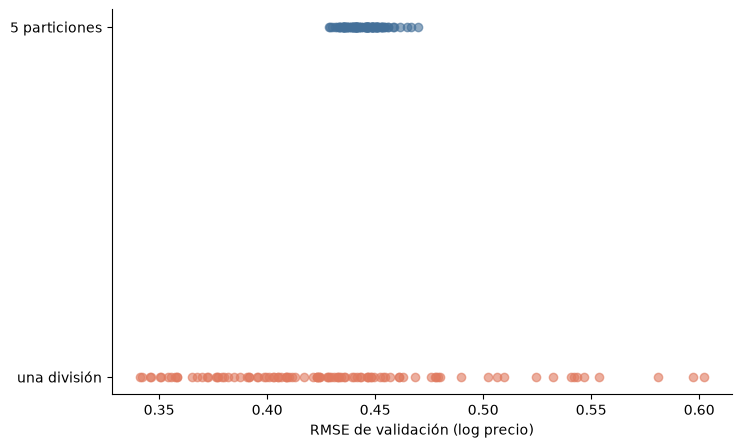

In [8]:
fig, ax = plt.subplots()
ax.scatter(una_division, np.zeros(100), color=TERRACOTA, alpha=0.6, label="una división 80/20")
ax.scatter(cinco_particiones, np.ones(100), color=AZUL, alpha=0.6, label="5 particiones")
ax.set_yticks([0, 1], ["una división", "5 particiones"])
ax.set_xlabel("RMSE de validación (log precio)")
plt.show()

## Slides 6 y 7. ¿Cuántas particiones? ¿Cuánto vale el error típico?

Simulación con `N_CONJUNTOS` rondas. En cada ronda elegimos al azar 300 anuncios (un conjunto) y el mismo Ridge se valida con k = 2, 5, 10 y LOOCV (k = n), y medimos su **error real** en 1 331 anuncios que no se usan en ningún ajuste. **Celda lenta (1-3 min): LOOCV hace 300 ajustes por conjunto.**

En la slide 7, cada ronda da dos números de la validación cruzada con 5 particiones: el **error estimado** y su **error típico** (desviación de los 5 errores de partición dividida por √5). La **variación real** es la desviación típica de los `N_CONJUNTOS` errores estimados: cuánto cambia la estimación con otros 300 anuncios.

In [9]:
# Anuncios de entrenamiento: unos sirven para extraer los conjuntos y otros miden el error real
reserva, no_usados = train_test_split(entreno, test_size=0.25, random_state=123)
opciones_k = {"k = 2": KFold(2, shuffle=True, random_state=SEED),
              "k = 5": KFold(5, shuffle=True, random_state=SEED),
              "k = 10": KFold(10, shuffle=True, random_state=SEED),
              "LOOCV": LeaveOneOut()}

filas = []
for b in range(N_CONJUNTOS):
    conjunto = reserva.sample(N_TRAIN, random_state=1000 + b)
    Xb, yb = conjunto[features], conjunto["log_precio"]

    # Error real: el modelo ajustado con los 300 anuncios, evaluado en los no usados
    modelo_b = clone(ridge_fijo).fit(Xb, yb)
    fila = {"real": root_mean_squared_error(no_usados["log_precio"], modelo_b.predict(no_usados[features]))}

    # Estimaciones por validación cruzada
    for k, cv_k in opciones_k.items():
        fila[k], mse = rmse_validacion(ridge_fijo, Xb, yb, cv_k)
        if k == "k = 5":
            # Error típico de esta ronda: desviación de los 5 errores de partición dividida por √5
            fila["ee_ingenuo"] = np.sqrt(mse).std(ddof=1) / np.sqrt(5)
    filas.append(fila)
conjuntos = pd.DataFrame(filas)
print("Anuncios no usados:", len(no_usados))

Anuncios no usados: 1331


In [10]:
# Slide 6: sesgo medio de cada estimación (estimación - error real)
for k in opciones_k:
    print(k, "sesgo medio:", round((conjuntos[k] - conjuntos["real"]).mean(), 4))

k = 2 sesgo medio: 0.0153
k = 5 sesgo medio: 0.0056
k = 10 sesgo medio: 0.0022
LOOCV sesgo medio: -0.0002


Media de los errores típicos: 0.024
Variación real (desviación de los errores estimados): 0.031


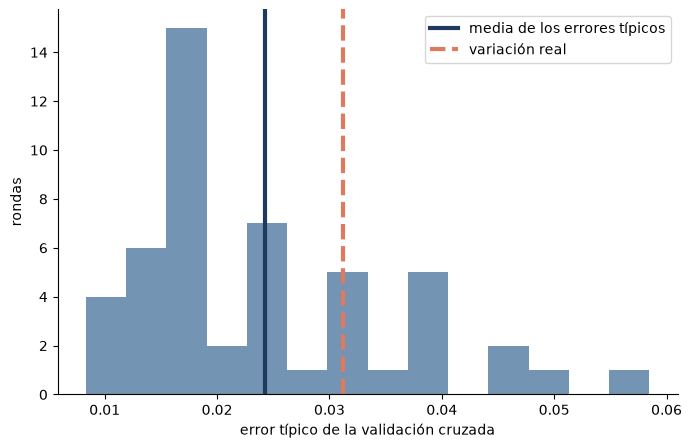

In [11]:
# Slide 7. Una fila por ronda: el error estimado con 5 particiones ("k = 5") y su error típico ("ee_ingenuo")
ee_medio = conjuntos["ee_ingenuo"].mean()          # media de los 50 errores típicos
variacion_real = conjuntos["k = 5"].std(ddof=1)    # desviación típica de los 50 errores estimados
print("Media de los errores típicos:", round(ee_medio, 3))
print("Variación real (desviación de los errores estimados):", round(variacion_real, 3))

fig, ax = plt.subplots()
ax.hist(conjuntos["ee_ingenuo"], bins=14, color=AZUL, alpha=0.75)
ax.axvline(ee_medio, color=MARINO, lw=3, label="media de los errores típicos")
ax.axvline(variacion_real, color=TERRACOTA, lw=3, ls="--", label="variación real")
ax.set_xlabel("error típico de la validación cruzada")
ax.set_ylabel("rondas")
ax.legend()
plt.show()

## Slide 8. Regla del error típico

Entre los modelos cuyo error no supera al mínimo en más de un error típico, elegimos el más sencillo (menos coeficientes no nulos).

In [12]:
limite = decision.loc[winner, "RMSE CV"] + decision.loc[winner, "EE CV"]
en_banda = decision[decision["RMSE CV"] <= limite]
elegido = en_banda["Activas"].idxmin()
print("Límite:", round(limite, 4))
print("Dentro de la banda:", list(en_banda.index))
print("La regla elige:", elegido)

Límite: 0.4375
Dentro de la banda: ['Lasso', 'Elastic Net']
La regla elige: Lasso


## Slide 9. Validación cruzada anidada

`cross_val_score(GridSearchCV(...), X, y, cv=5)`:

1. `cross_val_score` reserva una partición de `X` e `y` para **evaluar**;
2. `GridSearchCV` recibe las otras cuatro y hace su propia validación cruzada **interna** para elegir λ;
3. el modelo elegido se ajusta con esas cuatro y se evalúa en la reservada.

Ninguna observación interviene en la elección de λ de la vuelta en la que sirve para evaluar. El ejemplo usa solo Lasso. Para elegir también entre las tres familias, la elección se repite dentro de cada vuelta externa con las tres búsquedas de `busca`.

In [13]:
busqueda_lasso = GridSearchCV(pipeline(Lasso(max_iter=50000, tol=1e-5)), {"model__alpha": l1_grid},
                              cv=5, scoring="neg_mean_squared_error")
externa = KFold(5, shuffle=True, random_state=7)
mse_externos = -cross_val_score(busqueda_lasso, X_train, y_train, cv=externa,
                                scoring="neg_mean_squared_error")

print("Cinco errores externos (RMSE):", np.sqrt(mse_externos).round(3))
print("Anidada (RMSE):", round(np.sqrt(mse_externos.mean()), 3))
print("Mínimo de la validación cruzada de Lasso (best_score_):", round(np.sqrt(-searches["Lasso"].best_score_), 3))

Cinco errores externos (RMSE): [0.466 0.482 0.556 0.374 0.351]
Anidada (RMSE): 0.452
Mínimo de la validación cruzada de Lasso (best_score_): 0.422


# Bloque 2. ¿Cómo medimos la capacidad predictiva de un clasificador?

## Slide 12. ¿Es superanfitrión el anuncio?

Misma población y división. Respuesta: superanfitrión (1) o no (0). Predictores: los de la semana 2, sin superanfitrión y con log(precio). Se excluyen los anuncios sin dato.

In [14]:
num_c = [v for v in num if v != "superhost"] + ["log_precio"]
feat_c = num_c + cat
ent_c = entreno[entreno["host_is_superhost"].notna()]
test_c = test[test["host_is_superhost"].notna()]
X_c, y_c = ent_c[feat_c], ent_c["superhost"]
X_ct, y_ct = test_c[feat_c], test_c["superhost"]
print("Entrenamiento:", len(ent_c), "| test:", len(test_c), "| prevalencia:", round(y_c.mean(), 3))


def preprocesador_c():
    numericas = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())])
    # Barrios con menos de 50 anuncios: una categoría común
    categoricas = OneHotEncoder(drop=REF, min_frequency=50, handle_unknown="infrequent_if_exist",
                                sparse_output=False)
    return ColumnTransformer([("num", numericas, num_c), ("cat", categoricas, cat)])


# Logit sin penalización (C = infinito)
logit = Pipeline([("prep", preprocesador_c()),
                  ("model", LogisticRegression(C=np.inf, max_iter=5000))])

Entrenamiento: 5136 | test: 2199 | prevalencia: 0.305


Las métricas de los bloques 2 y 3 usan **predicciones de validación cruzada** en el conjunto de entrenamiento (`cross_val_predict`): se estima el logit con cuatro particiones y se predice la quinta, rotando hasta que las cinco han hecho de validación. Cada anuncio recibe una sola predicción, la de la vuelta en que su partición hacía de validación, y ningún modelo lo usó al estimarse. Detrás hay cinco logit con coeficientes distintos: se evalúa el procedimiento. Guardamos la probabilidad, así que la clase depende del umbral que elijamos después. Las particiones son estratificadas (misma proporción de superanfitriones en todas). El test sigue reservado.

In [15]:
cv_c = StratifiedKFold(5, shuffle=True, random_state=SEED)
p_oof = cross_val_predict(logit, X_c, y_c, cv=cv_c, method="predict_proba")[:, 1]   # probabilidad de ser superanfitrión
pred_05 = (p_oof >= 0.5).astype(int)                                                # clase con umbral 0,5

## Slide 13. Un clasificador nulo (*dummy*)

In [16]:
nulo = DummyClassifier(strategy="most_frequent")          # siempre «no es superanfitrión»
exactitud_nulo = cross_val_score(nulo, X_c, y_c, cv=cv_c, scoring="accuracy").mean()
print("Exactitud del nulo:", round(exactitud_nulo, 3))
print("Exactitud del logit:", round(accuracy_score(y_c, pred_05), 3))
print("Sensibilidad del logit:", round(recall_score(y_c, pred_05), 3))

Exactitud del nulo: 0.695
Exactitud del logit: 0.772
Sensibilidad del logit: 0.453


## Slides 14 y 15. Matriz de confusión, precisión, sensibilidad y F1

`ConfusionMatrixDisplay` dibuja la matriz en el orden de las etiquetas, 0 y después 1: arriba a la izquierda los verdaderos negativos (VN) y abajo a la derecha los verdaderos positivos (VP). `display_labels` solo cambia los rótulos de los ejes.

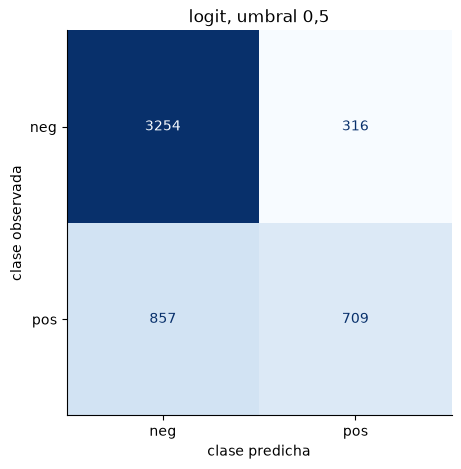

VN = 3254 | FP (error tipo I) = 316 | FN (error tipo II) = 857 | VP = 709


In [17]:
# Matriz de confusión: filas = clase observada, columnas = clase predicha
grafico = ConfusionMatrixDisplay.from_predictions(y_c, pred_05, display_labels=["neg", "pos"],
                                                  cmap="Blues", colorbar=False)
grafico.ax_.set(title="logit, umbral 0,5", xlabel="clase predicha", ylabel="clase observada")
plt.show()

# Los mismos recuentos como números: confusion_matrix usa el mismo orden (0, 1)
matriz = confusion_matrix(y_c, pred_05)
vn, fp = matriz[0]
fn, vp = matriz[1]
print("VN =", vn, "| FP (error tipo I) =", fp, "| FN (error tipo II) =", fn, "| VP =", vp)

In [18]:
precision = precision_score(y_c, pred_05)
sensibilidad = recall_score(y_c, pred_05)
especificidad = vn / (vn + fp)
f1 = f1_score(y_c, pred_05)
print("Precisión:", round(precision, 3))
print("Sensibilidad:", round(sensibilidad, 3))
print("Especificidad:", round(especificidad, 3))
print("F1:", round(f1, 3))

# F1 es la media armónica de precisión y sensibilidad, y también 2VP / (2VP + FP + FN)
print("Media armónica:", round(2 / (1 / precision + 1 / sensibilidad), 3))
print("2VP / (2VP + FP + FN):", round(2 * vp / (2 * vp + fp + fn), 3))

Precisión: 0.692
Sensibilidad: 0.453
Especificidad: 0.911
F1: 0.547
Media armónica: 0.547
2VP / (2VP + FP + FN): 0.547


## Slide 16. Métricas para distintos umbrales

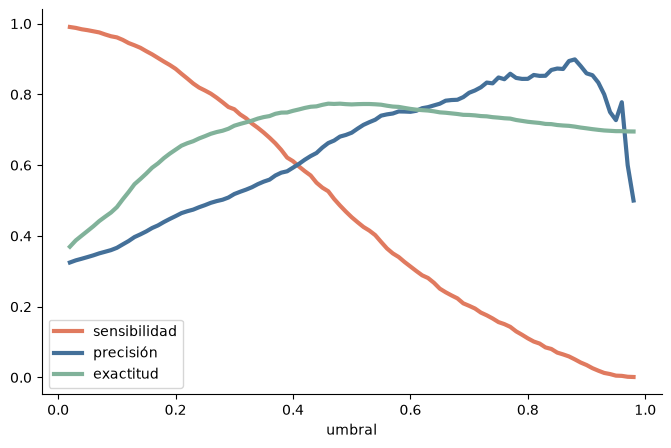

In [19]:
umbrales = np.linspace(0.02, 0.98, 97)
filas = []
for t in umbrales:
    pred_t = (p_oof >= t).astype(int)
    filas.append({"umbral": t,
                  "sensibilidad": recall_score(y_c, pred_t),
                  "precision": precision_score(y_c, pred_t, zero_division=np.nan),
                  "exactitud": accuracy_score(y_c, pred_t)})
por_umbral = pd.DataFrame(filas)

fig, ax = plt.subplots()
ax.plot(por_umbral["umbral"], por_umbral["sensibilidad"], color=TERRACOTA, lw=3, label="sensibilidad")
ax.plot(por_umbral["umbral"], por_umbral["precision"], color=AZUL, lw=3, label="precisión")
ax.plot(por_umbral["umbral"], por_umbral["exactitud"], color=SALVIA, lw=3, label="exactitud")
ax.set_xlabel("umbral")
ax.legend()
plt.show()

## Slides 17 y 18. Curva ROC y AUC (umbrales 0,5 y 0,3)

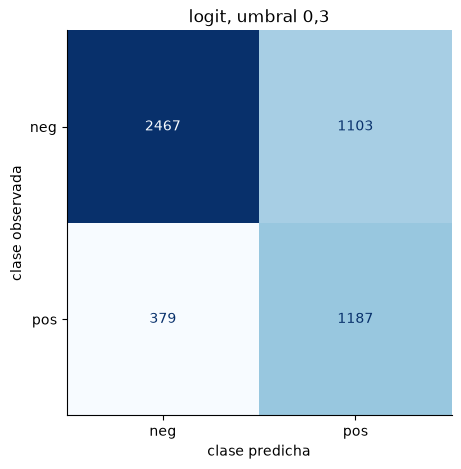

AUC: 0.803


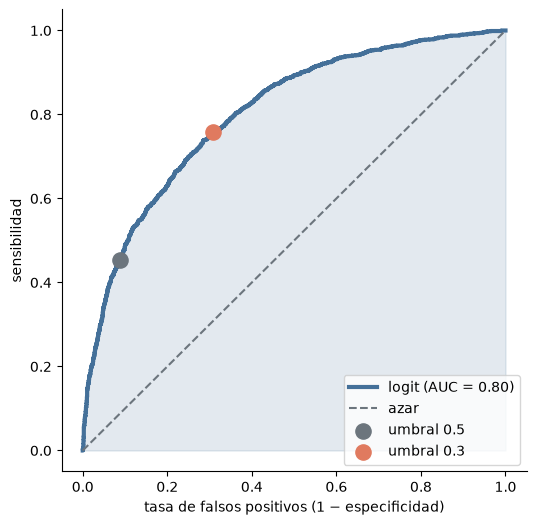

In [20]:
pred_03 = (p_oof >= 0.3).astype(int)
grafico = ConfusionMatrixDisplay.from_predictions(y_c, pred_03, display_labels=["neg", "pos"],
                                                  cmap="Blues", colorbar=False)
grafico.ax_.set(title="logit, umbral 0,3", xlabel="clase predicha", ylabel="clase observada")
plt.show()

fpr, tpr, _ = roc_curve(y_c, p_oof)          # una tasa de falsos positivos y una sensibilidad por umbral
auc = roc_auc_score(y_c, p_oof)
print("AUC:", round(auc, 3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.fill_between(fpr, tpr, color=AZUL, alpha=0.15)          # el área sombreada es el AUC
ax.plot(fpr, tpr, color=AZUL, lw=3, label=f"logit (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", label="azar")
for pred, t, color in [(pred_05, 0.5, GRIS), (pred_03, 0.3, TERRACOTA)]:
    tasa_fp = np.mean(pred[y_c == 0])          # proporción de negativos señalados
    sens = np.mean(pred[y_c == 1])             # proporción de positivos señalados
    ax.scatter(tasa_fp, sens, s=120, color=color, zorder=5, label=f"umbral {t}")
ax.set(xlabel="tasa de falsos positivos (1 − especificidad)", ylabel="sensibilidad")
ax.legend(loc="lower right")
plt.show()

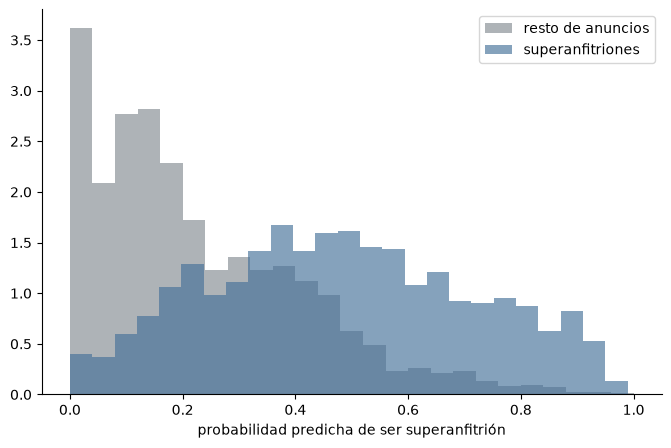

In [21]:
# Complemento de la slide 18: el AUC mide cuánto se separan estas dos distribuciones.
# Con AUC = 1 no se solaparían; con AUC = 0,5 coincidirían.
es_super = (y_c == 1).to_numpy()
fig, ax = plt.subplots()
ax.hist(p_oof[~es_super], bins=25, density=True, color=GRIS, alpha=0.55, label="resto de anuncios")
ax.hist(p_oof[es_super], bins=25, density=True, color=AZUL, alpha=0.65, label="superanfitriones")
ax.set_xlabel("probabilidad predicha de ser superanfitrión")
ax.legend()
plt.show()

## Slide 19. Log-loss

In [22]:
# Pérdida de una observación: -log de la probabilidad asignada a la clase observada
print("Acierto seguro (es superanfitrión, p = 0,9):", round(-np.log(0.9), 2))
print("Error seguro (no lo es, p = 0,9):", round(-np.log(1 - 0.9), 2))
print("Error muy seguro (no lo es, p = 0,99):", round(-np.log(1 - 0.99), 2))

# Nulo: predice para todos la prevalencia del entrenamiento
p_prior = cross_val_predict(DummyClassifier(strategy="prior"), X_c, y_c, cv=cv_c, method="predict_proba")[:, 1]
print("Log-loss del nulo:", round(log_loss(y_c, p_prior), 3))
print("Log-loss del logit:", round(log_loss(y_c, p_oof), 3))

Acierto seguro (es superanfitrión, p = 0,9): 0.11
Error seguro (no lo es, p = 0,9): 2.3
Error muy seguro (no lo es, p = 0,99): 4.61
Log-loss del nulo: 0.615
Log-loss del logit: 0.491


## Slide 20. Las métricas como valor de `scoring`

In [23]:
for metrica in ["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss", "average_precision"]:
    valores = cross_val_score(logit, X_c, y_c, cv=cv_c, scoring=metrica)
    print(f"{metrica:>18}: {valores.mean():.3f}")

          accuracy: 0.772


         precision: 0.693


            recall: 0.453


                f1: 0.547


           roc_auc: 0.804


      neg_log_loss: -0.491


 average_precision: 0.652


# Bloque 3. ¿Qué cambia cuando una clase es rara?

## Slide 23. Simulación con tres prevalencias

La puntuación de los positivos sigue una normal desplazada 1,2 desviaciones típicas respecto a la de los negativos (AUC ≈ 0,80, como el logit); la probabilidad es la calibrada de ese modelo. Solo cambia la proporción de positivos.

«Señaladas» es el número de observaciones con probabilidad de al menos 0,5. En las slides, la precisión no se da si hay menos de 30 señaladas: con un 1 % de positivos, la probabilidad calibrada casi nunca llega a 0,5 y la precisión se calcularía con muy pocas observaciones.

In [24]:
def simula(prevalencia, n, seed=SEED, d=1.2):
    rng = np.random.default_rng(seed)
    y = rng.random(n) < prevalencia                              # True = positivo
    puntuacion = rng.normal(np.where(y, d, 0.0), 1.0)
    log_odds = d * puntuacion - d ** 2 / 2 + np.log(prevalencia / (1 - prevalencia))
    p = 1 / (1 + np.exp(-log_odds))                              # probabilidad calibrada
    return y, p


simulaciones = {}
filas = []
for q in [0.30, 0.05, 0.01]:
    y_q, p_q = simula(q, 200_000)
    simulaciones[q] = (y_q, p_q)
    pred_q = p_q >= 0.5
    filas.append({"positivos": q,
                  "exactitud del nulo": 1 - y_q.mean(),
                  "exactitud del modelo": accuracy_score(y_q, pred_q),
                  "señaladas": pred_q.sum(),                         # observaciones con p >= 0,5
                  "precisión": precision_score(y_q, pred_q, zero_division=np.nan),
                  "sensibilidad": recall_score(y_q, pred_q),
                  "AUC": roc_auc_score(y_q, p_q),
                  "AP": average_precision_score(y_q, p_q)})
pd.DataFrame(filas).round(3)

,positivos,exactitud del nulo,exactitud del modelo,señaladas,precisión,sensibilidad,AUC,AP
0,0.30,0.699,0.770,40595,0.674,0.455,0.803,0.650
1,0.05,0.950,0.951,563,0.611,0.035,0.802,0.234
2,0.01,0.990,0.990,3,0.667,0.001,0.793,0.063


## Slide 24. La curva precisión-sensibilidad (PR) del logit

Precisión media (AP): 0.649 | referencia (prevalencia): 0.305


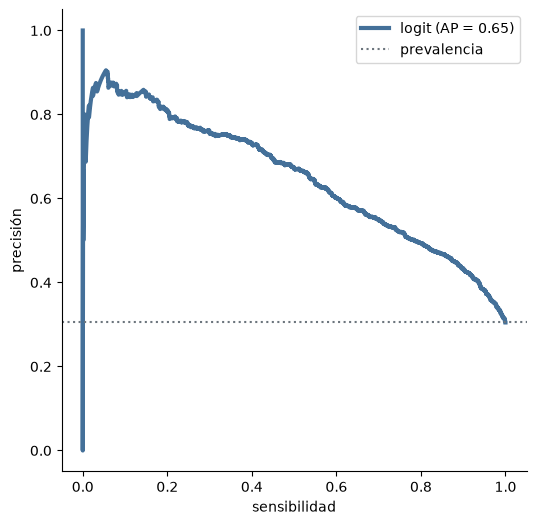

In [25]:
precisiones, sensibilidades, _ = precision_recall_curve(y_c, p_oof)
ap = average_precision_score(y_c, p_oof)
print("Precisión media (AP):", round(ap, 3), "| referencia (prevalencia):", round(y_c.mean(), 3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(sensibilidades, precisiones, color=AZUL, lw=3, label=f"logit (AP = {ap:.2f})")
ax.axhline(y_c.mean(), color=GRIS, ls=":", label="prevalencia")
ax.set(xlabel="sensibilidad", ylabel="precisión")
ax.legend()
plt.show()

## Slide 25. ROC y PR con tres prevalencias

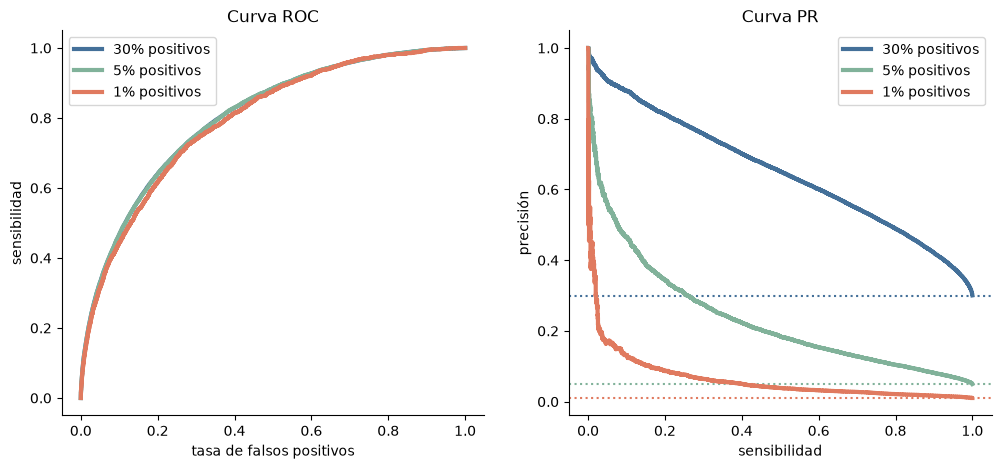

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for (q, (y_q, p_q)), color in zip(simulaciones.items(), [AZUL, SALVIA, TERRACOTA]):
    fpr_q, tpr_q, _ = roc_curve(y_q, p_q)
    ax1.plot(fpr_q, tpr_q, color=color, lw=3, label=f"{q:.0%} positivos")
    prec_q, sens_q, _ = precision_recall_curve(y_q, p_q)
    ax2.plot(sens_q, prec_q, color=color, lw=3, label=f"{q:.0%} positivos")
    ax2.axhline(q, color=color, ls=":")
ax1.set(title="Curva ROC", xlabel="tasa de falsos positivos", ylabel="sensibilidad")
ax2.set(title="Curva PR", xlabel="sensibilidad", ylabel="precisión")
ax1.legend()
ax2.legend()
plt.show()

## Slide 27. Costes asimétricos y umbral óptimo

Un falso positivo cuesta 1; un falso negativo, 4. Umbral teórico: 1 / (1 + 4) = 0,2. `TunedThresholdClassifierCV` busca el umbral con validación cruzada. **Celda algo lenta (unos 30 s).**

In [27]:
C_FP, C_FN = 1, 4


def coste_medio(y, pred):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    falsos_positivos = np.sum(pred & ~y)
    falsos_negativos = np.sum(~pred & y)
    return (C_FP * falsos_positivos + C_FN * falsos_negativos) / len(y)


print("Coste medio con umbral 0,5:", round(coste_medio(y_c, p_oof >= 0.5), 2))
print("Coste medio con umbral 0,2:", round(coste_medio(y_c, p_oof >= 0.2), 2))

ajustado = TunedThresholdClassifierCV(logit, scoring=make_scorer(coste_medio, greater_is_better=False),
                                      cv=cv_c, thresholds=umbrales)
ajustado.fit(X_c, y_c)
print("Umbral elegido por validación cruzada:", round(ajustado.best_threshold_, 2))

Coste medio con umbral 0,5: 0.73
Coste medio con umbral 0,2: 0.47
Umbral elegido por validación cruzada: 0.2


## Slides 28 y 29. `class_weight` cambia los pesos de estimación

Con `class_weight="balanced"`, cada observación de la clase k pesa n / (2 n_k) en la log-loss que se minimiza. En el logit, el cambio va sobre todo al intercepto; comparamos también las pendientes.

In [28]:
n = len(y_c)
n1 = int(y_c.sum())
n0 = n - n1
print("Peso de cada superanfitrión:", round(n / (2 * n1), 2))
print("Peso de cada anuncio del resto:", round(n / (2 * n0), 2))

logit_bal = Pipeline([("prep", preprocesador_c()),
                      ("model", LogisticRegression(C=np.inf, max_iter=5000, class_weight="balanced"))])
logit_fit = clone(logit).fit(X_c, y_c)
logit_bal_fit = clone(logit_bal).fit(X_c, y_c)
print("Intercepto sin ponderar:", round(logit_fit["model"].intercept_[0], 2))
print("Intercepto ponderado:", round(logit_bal_fit["model"].intercept_[0], 2))
print("log(n0 / n1):", round(np.log(n0 / n1), 2))

# Pendientes (predictores estandarizados, escala de log-odds): cuánto cambian al ponderar
nombres = logit_fit["prep"].get_feature_names_out()
pendientes = pd.DataFrame({"sin ponderar": logit_fit["model"].coef_[0],
                           "ponderado": logit_bal_fit["model"].coef_[0]}, index=nombres)
pendientes["cambio"] = pendientes["ponderado"] - pendientes["sin ponderar"]
print("Cambio del intercepto:", round(logit_bal_fit["model"].intercept_[0] - logit_fit["model"].intercept_[0], 2))
print("Mayor cambio de una pendiente:", round(pendientes["cambio"].abs().max(), 2))
print("Mediana del cambio de las pendientes:", round(pendientes["cambio"].abs().median(), 2))
pendientes.sort_values("cambio", key=abs, ascending=False).head(5).round(2)

Peso de cada superanfitrión: 1.64
Peso de cada anuncio del resto: 0.72
Intercepto sin ponderar: -1.66
Intercepto ponderado: -0.84
log(n0 / n1): 0.82
Cambio del intercepto: 0.82
Mayor cambio de una pendiente: 0.38
Mediana del cambio de las pendientes: 0.02


,sin ponderar,ponderado,cambio
cat__neighbourhood_cleansed_LA XEREA,-1.05,-0.67,0.38
num__review_scores_rating,1.83,1.67,-0.16
cat__neighbourhood_cleansed_AIORA,-0.17,-0.03,0.14
cat__neighbourhood_cleansed_SANT FRANCESC,-0.25,-0.12,0.13
cat__neighbourhood_cleansed_LA PETXINA,-0.31,-0.19,0.12


In [29]:
p_bal = cross_val_predict(logit_bal, X_c, y_c, cv=cv_c, method="predict_proba")[:, 1]
print("AUC sin ponderar:", round(roc_auc_score(y_c, p_oof), 3), "| ponderado:", round(roc_auc_score(y_c, p_bal), 3))
print("Probabilidad media sin ponderar:", round(p_oof.mean(), 3), "| ponderado:", round(p_bal.mean(), 3),
      "| prevalencia:", round(y_c.mean(), 3))
print("Log-loss sin ponderar:", round(log_loss(y_c, p_oof), 3), "| ponderado:", round(log_loss(y_c, p_bal), 3))

AUC sin ponderar: 0.803 | ponderado: 0.803
Probabilidad media sin ponderar: 0.306 | ponderado: 0.445 | prevalencia: 0.305
Log-loss sin ponderar: 0.491 | ponderado: 0.548


## Slide 31. Actividad final: la única consulta al test

Cuatro clasificadores ajustados con todo el entrenamiento y evaluados una sola vez en el test.

In [30]:
nulo_fit = DummyClassifier(strategy="prior").fit(X_c, y_c)
modelos = {"Nulo": (nulo_fit, 0.5),
           "Logit, umbral 0,5": (logit_fit, 0.5),
           "Logit ponderado": (logit_bal_fit, 0.5),
           "Logit, umbral por costes": (ajustado.estimator_, ajustado.best_threshold_)}

filas = []
for nombre, (modelo, umbral) in modelos.items():
    p_test = modelo.predict_proba(X_ct)[:, 1]
    pred_test = (p_test >= umbral).astype(int)
    filas.append({"Clasificador": nombre,
                  "Exactitud": accuracy_score(y_ct, pred_test),
                  "Precisión": precision_score(y_ct, pred_test, zero_division=np.nan),
                  "Sensibilidad": recall_score(y_ct, pred_test),
                  "AUC": roc_auc_score(y_ct, p_test),
                  "Log-loss": log_loss(y_ct, p_test),
                  "Coste medio": coste_medio(y_ct, pred_test)})
pd.DataFrame(filas).set_index("Clasificador").round(3)

,Exactitud,Precisión,Sensibilidad,AUC,Log-loss,Coste medio
Clasificador,,,,,,
Nulo,0.691,NaN,0.000,0.500,0.619,1.237
"Logit, umbral 0,5",0.768,0.692,0.449,0.818,0.479,0.744
Logit ponderado,0.739,0.555,0.781,0.819,0.531,0.464
"Logit, umbral por costes",0.654,0.468,0.878,0.818,0.479,0.459
